# Notebook 03 — Evaluation Suite

**Owner:** Role 5 — Evaluation Engineer  
**Purpose:** Evaluate the saved Random Forest, XGBoost, and TabNet models against the frozen held-out test set.

## Contract rules
- Load `data/processed/X_test.npy` and `data/processed/y_test.npy`. Do not re-split.
- Do not train, fit, or tune models in this notebook.
- Use `class_order.json` for class order and confusion-matrix labels.
- Use `feature_names.json` to validate feature ordering.
- Produce the three confusion matrices, two per-class metric CSVs, U2R/R2L PR curves, Macro F1 comparison, and `test_set_evaluation.json`.
- Review `paper_structure.md` §VI, `paper_narrative_context.md` §§9 and 13, and the model architecture report §7 before execution. If those contracts define a more specific schema, follow them.
- Run cells in order only after all model artifacts are available.

## 1. Imports and paths

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    average_precision_score, precision_recall_fscore_support,
    f1_score, accuracy_score
)

CWD = Path.cwd().resolve()
if (CWD / "data" / "processed").exists():
    ROOT = CWD
elif (CWD.parent / "data" / "processed").exists():
    ROOT = CWD.parent
else:
    raise FileNotFoundError("Open this notebook from the repository root or notebooks/ folder.")

DATA_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
OUTPUT_DIR = ROOT / "outputs" / "03_evaluation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", ROOT)
print("Output directory:", OUTPUT_DIR)

Repository: C:\SCHOOL\I.S. PROJECT\network-guardian-ids
Output directory: C:\SCHOOL\I.S. PROJECT\network-guardian-ids\outputs\03_evaluation


## 2. Verify all required inputs. Stop if anything is missing.

In [2]:
required_inputs = {
    "X_test": DATA_DIR / "X_test.npy",
    "y_test": DATA_DIR / "y_test.npy",
    "feature_names": DATA_DIR / "feature_names.json",
    "class_order": DATA_DIR / "class_order.json",
    "Random Forest": MODELS_DIR / "rf_baseline.joblib",
    "XGBoost": MODELS_DIR / "xgb_optuna.joblib",
    "TabNet": MODELS_DIR / "tabnet_best.zip",
}
missing = [f"{name}: {path}" for name, path in required_inputs.items() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing required inputs:\n- " + "\n- ".join(missing))
print("All required input files are present.")

All required input files are present.


## 3. Load the frozen test set and canonical metadata
No splitting, sampling, fitting, or tuning occurs here.

In [3]:
X_test = np.load(DATA_DIR / "X_test.npy", allow_pickle=False)
y_test_raw = np.load(DATA_DIR / "y_test.npy", allow_pickle=True).reshape(-1)

with open(DATA_DIR / "feature_names.json", encoding="utf-8") as f:
    feature_payload = json.load(f)
with open(DATA_DIR / "class_order.json", encoding="utf-8") as f:
    class_payload = json.load(f)

def extract_list(payload, candidates, name):
    if isinstance(payload, list):
        return [str(v) for v in payload]
    if isinstance(payload, dict):
        for key in candidates:
            if isinstance(payload.get(key), list):
                return [str(v) for v in payload[key]]
        if name == "class_order" and payload and all(str(k).isdigit() for k in payload):
            return [str(payload[k]) for k in sorted(payload, key=lambda x: int(x))]
    raise ValueError(f"Unrecognized {name}.json schema; inspect the contract and adapt this parser.")

feature_names = extract_list(feature_payload, ("feature_names", "features", "columns", "names"), "feature_names")
class_order = extract_list(class_payload, ("class_order", "classes", "class_names", "labels"), "class_order")

if X_test.ndim != 2 or len(X_test) != len(y_test_raw):
    raise ValueError(f"Unexpected test-array shapes: X={X_test.shape}, y={y_test_raw.shape}")
if X_test.shape[1] != len(feature_names):
    raise ValueError(f"X_test has {X_test.shape[1]} features but metadata has {len(feature_names)} names.")
if len(set(class_order)) != len(class_order):
    raise ValueError(f"Duplicate labels in class_order: {class_order}")

def canonical_label(value):
    if isinstance(value, (int, np.integer)) and 0 <= int(value) < len(class_order):
        return class_order[int(value)]
    if isinstance(value, (float, np.floating)) and float(value).is_integer():
        idx = int(value)
        if 0 <= idx < len(class_order):
            return class_order[idx]
    value = str(value)
    if value in class_order:
        return value
    raise ValueError(f"Label {value!r} cannot be mapped to class_order {class_order}.")

y_test = np.asarray([canonical_label(v) for v in y_test_raw], dtype=object)
print("X_test:", X_test.shape, "| y_test:", y_test.shape)
print("Features:", len(feature_names))
print("Canonical class order:", class_order)
print(pd.Series(y_test).value_counts().reindex(class_order, fill_value=0))

X_test: (36396, 43) | y_test: (36396,)
Features: 43
Canonical class order: ['normal', 'dos', 'probe', 'r2l', 'u2r']
normal    21958
dos       13643
probe       532
r2l         250
u2r          13
Name: count, dtype: int64


## 4. Load saved models only
This cell must not fit or retrain models.

In [4]:
rf_model = joblib.load(MODELS_DIR / "rf_baseline.joblib")
xgb_model = joblib.load(MODELS_DIR / "xgb_optuna.joblib")

try:
    from pytorch_tabnet.tab_model import TabNetClassifier
except ImportError as exc:
    raise ImportError("Install the project's pinned requirements to load TabNet.") from exc

tabnet_model = TabNetClassifier()
tabnet_model.load_model(str(MODELS_DIR / "tabnet_best.zip"))

models = {"rf": rf_model, "xgb": xgb_model, "tabnet": tabnet_model}
print("Loaded:", list(models))

Loaded: ['rf', 'xgb', 'tabnet']


C:\SCHOOL\I.S. PROJECT\network-guardian-ids\.venv\Lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


## 5. Generate predictions and align probability columns

Probability columns are aligned to `class_order.json` for U2R/R2L PR curves. If a model's output labels or probability-column mapping differs from the assumptions below, stop and adjust this cell to the model's metadata/contract rather than guessing.

In [5]:
def model_label(value):
    if isinstance(value, (int, np.integer)) and 0 <= int(value) < len(class_order):
        return class_order[int(value)]
    if isinstance(value, (float, np.floating)) and float(value).is_integer():
        idx = int(value)
        if 0 <= idx < len(class_order):
            return class_order[idx]
    value = str(value)
    if value in class_order:
        return value
    raise ValueError(f"Model output label {value!r} is not in canonical class order.")

def predict_and_align(model, X, name):
    y_pred = np.asarray([model_label(v) for v in np.asarray(model.predict(X)).reshape(-1)], dtype=object)
    if not hasattr(model, "predict_proba"):
        raise TypeError(f"{name} does not provide predict_proba(), required for PR curves.")
    raw_proba = np.asarray(model.predict_proba(X))
    if raw_proba.ndim != 2 or raw_proba.shape[0] != len(X):
        raise ValueError(f"{name} returned unexpected probability shape {raw_proba.shape}.")

    if hasattr(model, "classes_"):
        proba_labels = [model_label(v) for v in np.asarray(model.classes_).reshape(-1)]
    else:
        if raw_proba.shape[1] != len(class_order):
            raise ValueError(f"{name} has {raw_proba.shape[1]} probability columns but no classes_ mapping.")
        proba_labels = list(class_order)

    if len(proba_labels) != raw_proba.shape[1] or len(set(proba_labels)) != len(proba_labels):
        raise ValueError(f"{name}: probability columns do not map uniquely to classes.")
    aligned = np.zeros((len(X), len(class_order)), dtype=float)
    for j, label in enumerate(proba_labels):
        aligned[:, class_order.index(label)] = raw_proba[:, j]
    if not np.isfinite(aligned).all():
        raise ValueError(f"{name} returned non-finite probabilities.")
    return y_pred, aligned

predictions, probabilities = {}, {}
for name, model in models.items():
    predictions[name], probabilities[name] = predict_and_align(model, X_test, name)
    print(name, predictions[name].shape, probabilities[name].shape)

rf (36396,) (36396, 5)
xgb (36396,) (36396, 5)
tabnet (36396,) (36396, 5)


## 6. Confusion matrices
Required outputs: `confusion_matrix_rf.png`, `confusion_matrix_xgb.png`, `confusion_matrix_tabnet.png`.

In [6]:
for name in ("rf", "xgb", "tabnet"):
    cm = confusion_matrix(y_test, predictions[name], labels=class_order)
    fig, ax = plt.subplots(figsize=(9, 7))
    ConfusionMatrixDisplay(cm, display_labels=class_order).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False, xticks_rotation=45
    )
    ax.set_title(f"Confusion Matrix — {name.upper()}")
    filename = f"confusion_matrix_{name}.png"
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.text(0.01, 0.015, f"Caption: {name.upper()} confusion matrix on frozen test set. Source file: outputs/03_evaluation/{filename}", fontsize=8)
    fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", filename)

<Figure size 900x700 with 1 Axes>

Saved confusion_matrix_rf.png


<Figure size 900x700 with 1 Axes>

Saved confusion_matrix_xgb.png


<Figure size 900x700 with 1 Axes>

Saved confusion_matrix_tabnet.png


## 7. Per-class metrics

`per_class_metrics.csv` contains per-class precision, recall, F1, support, and model Macro F1. The normalized file keeps precision/recall/F1 on their natural 0–1 scale and adds `support_fraction` (class support divided by total support). If the project contract specifies a different normalized CSV schema, update this definition before running.

In [7]:
rows, normalized_rows = [], []
for name in ("rf", "xgb", "tabnet"):
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, predictions[name], labels=class_order, zero_division=0
    )
    macro_f1 = f1_score(y_test, predictions[name], labels=class_order, average="macro", zero_division=0)
    total = int(np.sum(support))
    for i, label in enumerate(class_order):
        row = {
            "model": name, "class": label,
            "precision": float(precision[i]), "recall": float(recall[i]),
            "f1": float(f1[i]), "support": int(support[i]), "macro_f1": float(macro_f1)
        }
        rows.append(row)
        normalized_rows.append({**row, "support_fraction": float(support[i] / total) if total else 0.0})

metrics_df = pd.DataFrame(rows)
normalized_df = pd.DataFrame(normalized_rows)
metrics_df.to_csv(OUTPUT_DIR / "per_class_metrics.csv", index=False)
normalized_df.to_csv(OUTPUT_DIR / "per_class_metrics_normalized.csv", index=False)
display(metrics_df)
print("Saved per_class_metrics.csv and per_class_metrics_normalized.csv")

,model,class,precision,recall,f1,support,macro_f1
0,rf,normal,0.998998,0.999408,0.999203,21958,0.933095
1,rf,dos,0.999780,0.999707,0.999743,13643,0.933095
2,rf,probe,0.992424,0.984962,0.988679,532,0.933095
3,rf,r2l,0.975410,0.952000,0.963563,250,0.933095
4,rf,u2r,0.666667,0.769231,0.714286,13,0.933095
5,xgb,normal,0.999544,0.999044,0.999294,21958,0.945134
6,xgb,dos,0.999707,0.999560,0.999633,13643,0.945134
7,xgb,probe,0.985019,0.988722,0.986867,532,0.945134
8,xgb,r2l,0.950192,0.992000,0.970646,250,0.945134
9,xgb,u2r,0.769231,0.769231,0.769231,13,0.945134


Saved per_class_metrics.csv and per_class_metrics_normalized.csv


## 8. U2R and R2L precision-recall curves

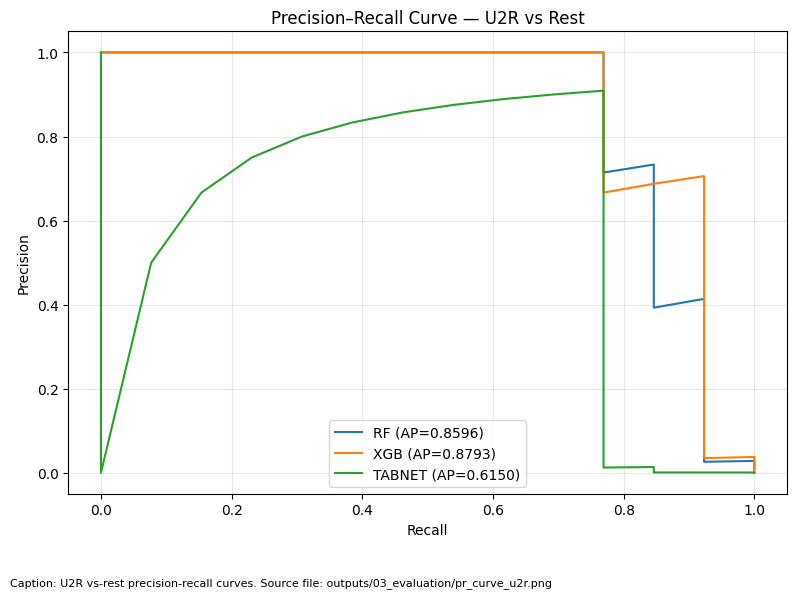

Saved pr_curve_u2r.png


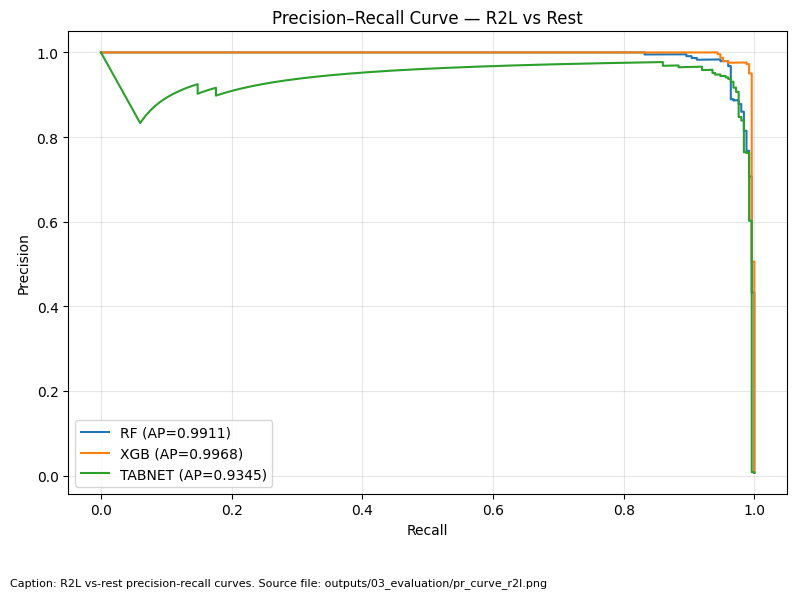

Saved pr_curve_r2l.png


In [8]:
for target in ("u2r", "r2l"):
    if target not in class_order:
        raise ValueError(f"Required class {target!r} is missing from class_order={class_order}")
    idx = class_order.index(target)
    y_binary = (y_test == target).astype(int)
    if len(np.unique(y_binary)) < 2:
        warnings.warn(f"Only one target value for {target} in test set; PR curve/AP may be uninformative.")

    fig, ax = plt.subplots(figsize=(8, 6))
    for name in ("rf", "xgb", "tabnet"):
        scores = probabilities[name][:, idx]
        p, r, _ = precision_recall_curve(y_binary, scores)
        ap = average_precision_score(y_binary, scores)
        ax.plot(r, p, label=f"{name.upper()} (AP={ap:.4f})")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title(f"Precision–Recall Curve — {target.upper()} vs Rest")
    ax.grid(True, alpha=0.3)
    ax.legend()
    filename = f"pr_curve_{target}.png"
    fig.tight_layout(rect=(0, 0.07, 1, 1))
    fig.text(0.01, 0.015, f"Caption: {target.upper()} vs-rest precision-recall curves. Source file: outputs/03_evaluation/{filename}", fontsize=8)
    fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Saved", filename)

## 9. Macro F1 comparison across the three models

,model,macro_f1,accuracy,test_samples
0,rf,0.933095,0.998901,36396
1,xgb,0.945134,0.998956,36396
2,tabnet,0.930622,0.997555,36396


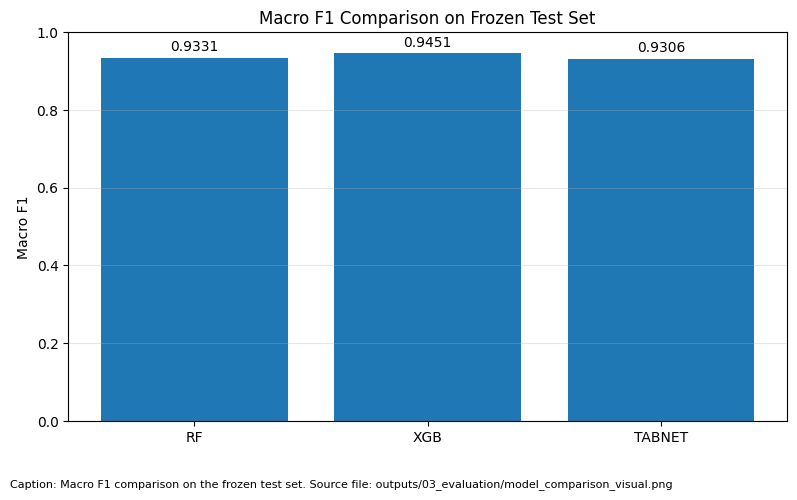

Saved model_comparison_visual.png


In [9]:
comparison_rows = []
for name in ("rf", "xgb", "tabnet"):
    comparison_rows.append({
        "model": name,
        "macro_f1": float(f1_score(y_test, predictions[name], labels=class_order, average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(y_test, predictions[name])),
        "test_samples": int(len(y_test)),
    })
comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(comparison_df["model"].str.upper(), comparison_df["macro_f1"])
ax.set_ylabel("Macro F1")
ax.set_title("Macro F1 Comparison on Frozen Test Set")
ax.set_ylim(0, min(1.0, max(0.05, float(comparison_df["macro_f1"].max()) * 1.15)))
ax.grid(axis="y", alpha=0.3)
ax.bar_label(bars, fmt="%.4f", padding=3)
filename = "model_comparison_visual.png"
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.text(0.01, 0.015, f"Caption: Macro F1 comparison on the frozen test set. Source file: outputs/03_evaluation/{filename}", fontsize=8)
fig.savefig(OUTPUT_DIR / filename, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved", filename)

## 10. Save the test-set evaluation record
The project source pointer index identifies `outputs/03_evaluation/test_set_evaluation.json` as the source for test-set evaluation.

In [10]:
record = {
    "evaluation_type": "frozen_held_out_test_set",
    "test_samples": int(len(y_test)),
    "n_features": int(X_test.shape[1]),
    "class_order": list(class_order),
    "source_artifacts": {
        "rf": "models/rf_baseline.joblib",
        "xgb": "models/xgb_optuna.joblib",
        "tabnet": "models/tabnet_best.zip",
    },
    "models": {},
}
for name in ("rf", "xgb", "tabnet"):
    p, r, f1, support = precision_recall_fscore_support(
        y_test, predictions[name], labels=class_order, zero_division=0
    )
    record["models"][name] = {
        "accuracy": float(accuracy_score(y_test, predictions[name])),
        "macro_f1": float(f1_score(y_test, predictions[name], labels=class_order, average="macro", zero_division=0)),
        "per_class": {
            label: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f1[i]), "support": int(support[i])}
            for i, label in enumerate(class_order)
        },
    }

with open(OUTPUT_DIR / "test_set_evaluation.json", "w", encoding="utf-8") as f:
    json.dump(record, f, indent=2)
print("Saved", OUTPUT_DIR / "test_set_evaluation.json")

Saved C:\SCHOOL\I.S. PROJECT\network-guardian-ids\outputs\03_evaluation\test_set_evaluation.json


## 11. Output verification

In [11]:
required_outputs = [
    "confusion_matrix_rf.png", "confusion_matrix_xgb.png", "confusion_matrix_tabnet.png",
    "per_class_metrics.csv", "per_class_metrics_normalized.csv",
    "pr_curve_u2r.png", "pr_curve_r2l.png", "model_comparison_visual.png",
    "test_set_evaluation.json",
]
status = pd.DataFrame([
    {"file": name, "exists": (OUTPUT_DIR / name).is_file(),
     "bytes": (OUTPUT_DIR / name).stat().st_size if (OUTPUT_DIR / name).is_file() else None}
    for name in required_outputs
])
display(status)
missing = status.loc[~status["exists"], "file"].tolist()
if missing:
    print("Missing outputs:", missing)
else:
    print("All listed Phase 3 outputs exist.")
print("Do not commit model/artifact files yourself if Kit's instructions assign those commits to him.")

,file,exists,bytes
0,confusion_matrix_rf.png,True,71561
1,confusion_matrix_xgb.png,True,72502
2,confusion_matrix_tabnet.png,True,74009
3,per_class_metrics.csv,True,1376
4,per_class_metrics_normalized.csv,True,1699
5,pr_curve_u2r.png,True,85685
6,pr_curve_r2l.png,True,78525
7,model_comparison_visual.png,True,51465
8,test_set_evaluation.json,True,3404


All listed Phase 3 outputs exist.
Do not commit model/artifact files yourself if Kit's instructions assign those commits to him.


## 12. Phase 3 handoff checklist

- [ ] Confirm the model files are the approved artifacts from Amber, Kenneth, and the TabNet run.
- [ ] Confirm the frozen test set was used without re-splitting.
- [ ] Review all confusion matrices and per-class metrics, especially U2R and R2L.
- [ ] Verify all required output files exist and open correctly.
- [ ] Ensure figure captions identify their source filenames.
- [ ] Write `docs/reports/role-5-phase-3-dwayne-evaluation-suite.md` with environment, outputs, and observed results.
- [ ] Notify Markie when the figures are ready for paper integration.
- [ ] Follow Kit's branch/PR and artifact-commit instructions.

Do not tune or retrain models based on held-out test results. Report unexpected results for review.